## **Data loading**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import plotly.express as px


df = pd.read_csv("Air_Traffic_Passenger_Statistics_20251204.csv")

if df['Passenger Count'].dtype == 'O':
    df['Passenger Count'] = df['Passenger Count'].str.replace(',', '').astype(int)
#Mothly data
monthly_data = df.groupby('Activity Period')['Passenger Count'].sum().reset_index()

# Convert to datetime for proper plotting
monthly_data['Date'] = pd.to_datetime(monthly_data['Activity Period'].astype(str), format='%Y%m')
monthly_data = monthly_data.sort_values('Date')
dataset_values = monthly_data['Passenger Count'].values.reshape(-1, 1)

# Ploting
fig = px.line(
    monthly_data,
    x="Date",
    y="Passenger Count",
    title="Pasajeros Totales por Año (SFO)",
    labels={"Date": "Año", "Passenger Count": "Pasajeros"}
)

fig.update_layout(
    xaxis_title="Año",
    yaxis_title="Pasajeros",
    template="plotly_white",
    width=900,
    height=450
)

fig.show()



### Importing ML libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

In [3]:
# fix random seed for reproducibility
tf.random.set_seed(7)

## **Data preparation for LTSM**

Spit the data in **train** and **test**

In [4]:
train_size = int(len(dataset_values) * 0.8)

train = dataset_values[:train_size]
test = dataset_values[train_size:]

Scale *train* first and then *test*

In [5]:
scaler = MinMaxScaler(feature_range=(0,1))

train_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)

def create_dataset(dataset, lookback=1):
    X_data, Y_data = [], []
    for i in range(len(dataset) - lookback - 1):
        a = dataset[i:i+lookback, 0]
        X_data.append(a)
        Y_data.append(dataset[i + lookback, 0])
    return np.array(X_data), np.array(Y_data)

Create data set

In [6]:
look_back = 3

trainX, trainY = create_dataset(train_scaled, look_back)
testX, testY = create_dataset(test_scaled, look_back)


In [7]:
trainX = trainX.reshape(trainX.shape[0], trainX.shape[1], 1)
testX  = testX.reshape(testX.shape[0],  testX.shape[1],  1)

Define model

In [8]:
model = Sequential()

model.add(LSTM(32, input_shape=(look_back, 1)))
model.add(Dropout(0.05))
model.add(Dense(1))

model.compile(loss='mean_squared_error', optimizer='adam')


2025-12-05 21:53:04.948003: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2025-12-05 21:53:04.948050: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2025-12-05 21:53:04.948061: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2025-12-05 21:53:04.948351: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-12-05 21:53:04.948638: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
/opt/anaconda3/envs/tf_lstm/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Runing the model

In [10]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    trainX, trainY,
    epochs=300,
    batch_size=1,
    verbose=2,
    validation_data=(testX, testY),
    callbacks=[early_stop]

)

Epoch 1/300


2025-12-05 21:53:05.631702: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


248/248 - 4s - 15ms/step - loss: 0.0428 - val_loss: 0.0101
Epoch 2/300
248/248 - 3s - 10ms/step - loss: 0.0105 - val_loss: 0.0082
Epoch 3/300
248/248 - 2s - 9ms/step - loss: 0.0107 - val_loss: 0.0074
Epoch 4/300
248/248 - 2s - 10ms/step - loss: 0.0096 - val_loss: 0.0070
Epoch 5/300
248/248 - 3s - 10ms/step - loss: 0.0098 - val_loss: 0.0070
Epoch 6/300
248/248 - 2s - 8ms/step - loss: 0.0087 - val_loss: 0.0065
Epoch 7/300
248/248 - 2s - 8ms/step - loss: 0.0083 - val_loss: 0.0065
Epoch 8/300
248/248 - 2s - 8ms/step - loss: 0.0083 - val_loss: 0.0067
Epoch 9/300
248/248 - 2s - 8ms/step - loss: 0.0089 - val_loss: 0.0072
Epoch 10/300
248/248 - 2s - 8ms/step - loss: 0.0087 - val_loss: 0.0063
Epoch 11/300
248/248 - 2s - 8ms/step - loss: 0.0075 - val_loss: 0.0061
Epoch 12/300
248/248 - 2s - 8ms/step - loss: 0.0075 - val_loss: 0.0059
Epoch 13/300
248/248 - 2s - 8ms/step - loss: 0.0076 - val_loss: 0.0057
Epoch 14/300
248/248 - 2s - 8ms/step - loss: 0.0074 - val_loss: 0.0055
Epoch 15/300
248/248 - 

In [11]:
import plotly.graph_objects as go

# Crear figura
fig_loss = go.Figure()

# 1. Train Loss
fig_loss.add_trace(go.Scatter(
    y=history.history['loss'],
    mode='lines',
    name='Train Loss',
    line=dict(color='#FF3344', width=3)
))

# 2. Validation/Test Loss
fig_loss.add_trace(go.Scatter(
    y=history.history['val_loss'],
    mode='lines',
    name='Test Loss',
    line=dict(color='#00CC96', width=3)
))

# Configuración del diseño
fig_loss.update_layout(
    title='Curva de Aprendizaje: Training vs Test Loss',
    xaxis_title='Epoch',
    yaxis_title='Loss (MSE)',
    template='plotly_white',
    legend=dict(x=1, y=1), # Leyenda arriba a la derecha
    width=900,
    height=500
)

fig_loss.show()

In [12]:
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

trainY_inv = scaler.inverse_transform(trainY.reshape(-1,1))
testY_inv  = scaler.inverse_transform(testY.reshape(-1,1))

trainPredict_inv = scaler.inverse_transform(trainPredict)
testPredict_inv  = scaler.inverse_transform(testPredict)

train_rmse = np.sqrt(mean_squared_error(trainY_inv, trainPredict_inv))
test_rmse  = np.sqrt(mean_squared_error(testY_inv,  testPredict_inv))

print("Train RMSE:", train_rmse)
print("Test RMSE: ", test_rmse)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Train RMSE: 378087.5560710922
Test RMSE:  351302.94393624086


In [13]:
import numpy as np
import plotly.graph_objects as go

# array vacío para graficar
trainPredictPlot = np.empty_like(dataset_values, dtype=float)
trainPredictPlot[:] = np.nan
trainPredictPlot[look_back:len(trainPredict_inv)+look_back, 0] = trainPredict_inv[:,0]

testPredictPlot = np.empty_like(dataset_values, dtype=float)
testPredictPlot[:] = np.nan
test_start = train_size + look_back
testPredictPlot[test_start:test_start+len(testPredict_inv), 0] = testPredict_inv[:,0]

# gráfico
fig = go.Figure()

# 1. Actual Data (Datos Reales)
fig.add_trace(go.Scatter(
    y=dataset_values[:,0],
    mode='lines',
    name='Actual Data',  # Traducido
    line=dict(color="#32C7F9")
))

# 2. Train Prediction
fig.add_trace(go.Scatter(
    y=trainPredictPlot[:,0],
    mode='lines',
    name='Train Predictions', # Traducido
    line=dict(color="#FD4A59", width=4)
))

# 3. Test Prediction
fig.add_trace(go.Scatter(
    y=testPredictPlot[:,0],
    mode='lines',
    name='Test Predictions', # Traducido
    line=dict(color='#00CC96', width=4)
))

# Configuración del diseño
fig.update_layout(
    title='Airline Passenger Traffic Forecast (LSTM)', # Traducido
    xaxis_title='Time (Months)', # Traducido
    yaxis_title='Passenger Count', # Traducido
    template='plotly_white',
    legend=dict(x=0, y=1, traceorder="normal"),
    width=1000, 
    height=500
)

fig.show()

In [14]:
# 1. Escalar todo el dataset si no lo tenías
data_scaled = scaler.transform(dataset_values)

# 2. Obtener la última ventana
last_window = data_scaled[-look_back:]

# 3. Reshape para el LSTM
last_window = last_window.reshape(1, look_back, 1)

# 4. Predicción
next_scaled = model.predict(last_window)

# 5. Desescalar
next_value = scaler.inverse_transform(next_scaled)
print("Predicción del próximo mes:", next_value[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Predicción del próximo mes: 4311051.0


In [15]:
from pandas.tseries.offsets import DateOffset
import pandas as pd

future_months = 14
future_predictions = []

# Obtenemos la última ventana de datos reales escalados
last_window = data_scaled[-look_back:]
current_batch = last_window.reshape((1, look_back, 1))

print("Iniciando predicción para los próximos 12 meses...")

for i in range(future_months):
    # Predecir el siguiente valor
    # verbose=0 para no llenar la pantalla de logs
    current_pred = model.predict(current_batch, verbose=0)[0]
    
    # Guardar la predicción
    future_predictions.append(current_pred)
    
    # Actualizar el batch: 
    # Quitamos el primer elemento (el más viejo) y agregamos la nueva predicción al final
    current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

# Invertir la escala
future_predictions = scaler.inverse_transform(future_predictions)

#Futures dates
last_date = monthly_data['Date'].iloc[-1]

future_dates = [last_date + DateOffset(months=x) for x in range(1, future_months + 1)]

#Plot
fig = go.Figure()

# Datos Históricos
fig.add_trace(go.Scatter(
    x=monthly_data['Date'],
    y=dataset_values.flatten(),
    mode='lines',
    name='Históricos',
    line=dict(color='#32C7F9')
))

# Predicciones Futuras
fig.add_trace(go.Scatter(
    x=future_dates,
    y=future_predictions.flatten(),
    mode='lines+markers', # Markers para ver claramente cada mes predicho
    name=f'Proyección',
    line=dict(color="#70DE17", width=3, dash='dash') # Línea punteada para distinguir el futuro
))

fig.update_layout(
    title=f'Proyección de Tráfico de Pasajeros (Próximos {future_months} Meses)',
    xaxis_title='Fecha',
    yaxis_title='Pasajeros',
    template='plotly_white',
    legend=dict(x=0, y=1),
    width=1000,
    height=500
)

fig.show()

# Imprimir los valores numéricos
print("\nValores predichos:")
for date, val in zip(future_dates, future_predictions):
    print(f"{date.strftime('%Y-%m')}: {int(val[0])} pasajeros")

Iniciando predicción para los próximos 12 meses...



Valores predichos:
2025-10: 4311050 pasajeros
2025-11: 4265782 pasajeros
2025-12: 4269382 pasajeros
2026-01: 4285360 pasajeros
2026-02: 4306992 pasajeros
2026-03: 4329017 pasajeros
2026-04: 4350146 pasajeros
2026-05: 4369702 pasajeros
2026-06: 4387571 pasajeros
2026-07: 4403770 pasajeros
2026-08: 4418397 pasajeros
2026-09: 4431569 pasajeros
2026-10: 4443407 pasajeros
2026-11: 4454033 pasajeros


## **Terminal dataset**

In [16]:
df = pd.read_csv("Air_Traffic_Passenger_Statistics_20251204.csv")

if df['Passenger Count'].dtype == 'O':
    df['Passenger Count'] = df['Passenger Count'].str.replace(',', '').astype(int)

df["Year"] = df["Activity Period"].astype(str).str[:4]

#Create pivot table
tabla_terminales = df.pivot_table(
    index="Year",
    columns="Terminal",
    values="Passenger Count",
    aggfunc="sum"
)

tabla_terminales = tabla_terminales.sort_index()

terminales = ['Terminal 1', 'Terminal 2', 'Terminal 3', 'Other', 'International']

tabla_terminales = tabla_terminales[terminales]

tabla_terminales["Sum of terminals"] = tabla_terminales.sum(axis=1)

tabla_total_original = df.pivot_table(
    index="Year",
    values="Passenger Count",
    aggfunc="sum"
)

tabla_terminales["Dataset Count"] = tabla_total_original["Passenger Count"]

comparacion = tabla_terminales["Sum of terminals"] == tabla_terminales["Dataset Count"]

# 2. Verificamos: Si NO todos son verdaderos (es decir, hay algún False), añadimos la columna
if not comparacion.all():
    tabla_terminales["boleano"] = comparacion
    print("¡Atención! Se encontraron diferencias, se ha añadido la columna 'boleano'.")
else:
    print("Todos los totales coinciden. No se añadió la columna 'boleano'.")

tabla_terminales["Terminal 1 %"] = (tabla_terminales["Terminal 1"] / tabla_terminales["Dataset Count"]) * 100
tabla_terminales["Terminal 2 %"] = (tabla_terminales["Terminal 2"] / tabla_terminales["Dataset Count"]) * 100
tabla_terminales["Terminal 3 %"] = (tabla_terminales["Terminal 3"] / tabla_terminales["Dataset Count"]) * 100
tabla_terminales["Other %"] = (tabla_terminales["Other"] / tabla_terminales["Dataset Count"]) * 100
tabla_terminales["International %"] = (tabla_terminales["International"] / tabla_terminales["Dataset Count"]) * 100



tabla_terminales

Todos los totales coinciden. No se añadió la columna 'boleano'.


Terminal,Terminal 1,Terminal 2,Terminal 3,Other,International,Sum of terminals,Dataset Count,Terminal 1 %,Terminal 2 %,Terminal 3 %,Other %,International %
Year,,,,,,,,,,,,
1999,5421195.0,3012995.0,11447224.0,NaN,1101218.0,20982632.0,20982632,25.836582,14.359471,54.555711,NaN,5.248236
2000,11113290.0,5537949.0,20966686.0,90.0,3073426.0,40691441.0,40691441,27.311124,13.609616,51.526035,0.000221,7.553004
2001,8353524.0,NaN,17855547.0,NaN,8078253.0,34287324.0,34287324,24.363301,NaN,52.076234,NaN,23.560465
2002,7406327.0,NaN,15993244.0,NaN,7691763.0,31091334.0,31091334,23.821194,NaN,51.439555,NaN,24.739250
2003,7143525.0,NaN,14850969.0,66.0,7055168.0,29049728.0,29049728,24.590678,NaN,51.122575,0.000227,24.286520
2004,8083990.0,NaN,16544485.0,NaN,7822032.0,32450507.0,32450507,24.911753,NaN,50.983749,NaN,24.104499
2005,8000007.0,NaN,16659131.0,18.0,8440054.0,33099210.0,33099210,24.169782,NaN,50.330902,0.000054,25.499261
2006,7882651.0,NaN,17386754.0,47.0,8063518.0,33332970.0,33332970,23.648211,NaN,52.160831,0.000141,24.190818
2007,9112748.0,NaN,17878748.0,46.0,8562540.0,35554082.0,35554082,25.630666,NaN,50.286063,0.000129,24.083142


In [17]:
col_percentage = ["Terminal 1 %",
                  "Terminal 2 %",
                  "Terminal 3 %",
                  "Other %",
                  "International %"]

cols_existentes = [c for c in col_percentage if c in tabla_terminales.columns]

fig1 = go.Figure()

for col in cols_existentes:
    fig1.add_trace(go.Scatter(
        x=tabla_terminales.index,
        y=tabla_terminales[col],
        mode="lines+markers",
        name=col
    ))

fig1.update_layout(
    title="Evolución de la Distribución de Pasajeros por Terminal (%)",
    xaxis_title="Año",
    yaxis_title="Porcentaje de Tráfico",
    template="plotly_white",
    hovermode="x unified"
)

fig1.show()

std_dev_por_anio = tabla_terminales[cols_existentes].std(axis=1)

fig2 = px.line(
    std_dev_por_anio,
    x=std_dev_por_anio.index,
    y=std_dev_por_anio.values,
    title="Desviación Estándar del Tráfico por Año (Equilibrio entre Terminales)",
    labels={"x": "Año", "y": "Desviación (Mayor = Menos equilibrio)"},
)

fig2.update_traces(mode="lines+markers")
fig2.update_layout(template="plotly_white")

fig2.show()

# Mostrar los años más equilibrados
print("Años con mejor equilibrio (menor desviación estándar):")
print(std_dev_por_anio.sort_values().head(5))

Años con mejor equilibrio (menor desviación estándar):
Year
2012    7.887567
2010    8.411428
2025    8.555844
2014    8.913089
2024    9.111766
dtype: float64


## Future predictions

Predicción LSTM Total Año Siguiente: 61,026,187 pasajeros


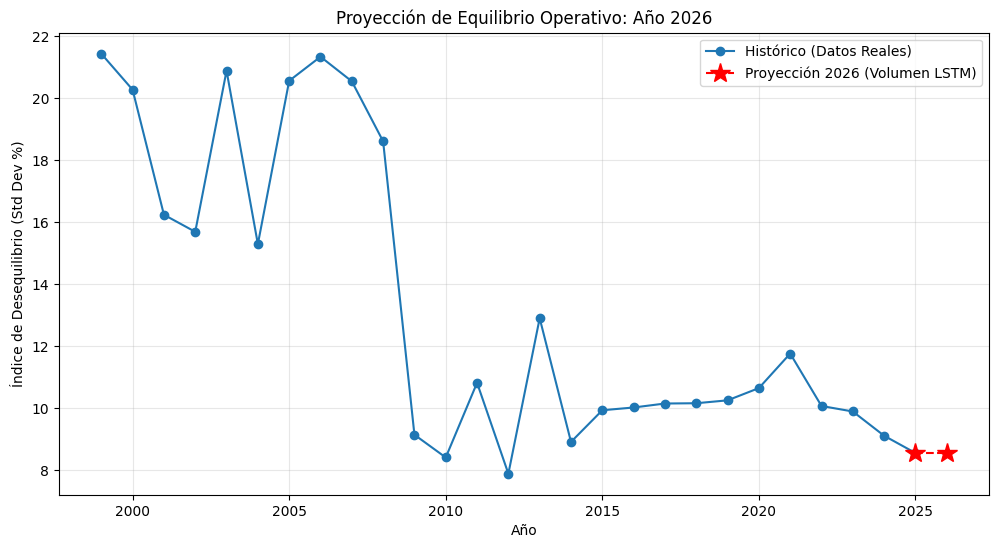


--- ESCENARIO PREDICTIVO POR TERMINAL ---
Terminal
Terminal 1 %       16,429,414 pasajeros
Terminal 2 %        7,604,422 pasajeros
Terminal 3 %       19,153,848 pasajeros
Other %                   nan pasajeros
International %    17,838,503 pasajeros
Name: 2025, dtype: object


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# PASO 1: Obtener el VOLUMEN Total del LSTM
# ---------------------------------------------------------
# Sumamos los 12 meses que predijo tu modelo para obtener el total anual
# Asumimos que la variable 'future_predictions' contiene los datos ya des-escalados
prediccion_total_anual = np.sum(future_predictions)

print(f"Predicción LSTM Total Año Siguiente: {prediccion_total_anual:,.0f} pasajeros")

# ---------------------------------------------------------
# PASO 2: Definir la ESTRUCTURA (Distribución de Terminales)
# ---------------------------------------------------------
# Hipótesis: Asumimos que la distribución se mantiene igual al último año conocido ("Status Quo").
# Si supieras que una terminal se va a expandir, podrías ajustar estos % manualmente.

columnas_porcentaje = [c for c in tabla_terminales.columns if "%" in c]

# Tomamos los % del último año registrado en tus datos
distribucion_ultimo_anio = tabla_terminales.iloc[-1][columnas_porcentaje]

# ---------------------------------------------------------
# PASO 3: Calcular el ESCENARIO FUTURO
# ---------------------------------------------------------
# Aplicamos el Volumen del LSTM a la Estructura de Terminales
pasajeros_futuros_por_terminal = (distribucion_ultimo_anio / 100) * prediccion_total_anual

# Calculamos el índice de desequilibrio (Desviación Estándar) para este futuro
desequilibrio_futuro = distribucion_ultimo_anio.std()

# ---------------------------------------------------------
# PASO 4: VISUALIZACIÓN COMBINADA
# ---------------------------------------------------------
# 1. Preparamos los datos históricos
std_dev_historica = tabla_terminales[columnas_porcentaje].std(axis=1)

# 2. Definimos el año futuro (el siguiente al último de tu tabla)
ultimo_anio = int(tabla_terminales.index[-1])
anio_futuro = ultimo_anio + 1

# 3. Graficamos
plt.figure(figsize=(12, 6))

# Línea histórica
plt.plot(tabla_terminales.index.astype(int), std_dev_historica, 
         marker='o', label='Histórico (Datos Reales)')

# Punto de proyección (Conectamos el último año real con la predicción)
plt.plot([ultimo_anio, anio_futuro], 
         [std_dev_historica.iloc[-1], desequilibrio_futuro], 
         color='red', linestyle='--', marker='*', markersize=15, 
         label=f'Proyección {anio_futuro} (Volumen LSTM)')

plt.title(f"Proyección de Equilibrio Operativo: Año {anio_futuro}")
plt.xlabel("Año")
plt.ylabel("Índice de Desequilibrio (Std Dev %)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\n--- ESCENARIO PREDICTIVO POR TERMINAL ---")
print(pasajeros_futuros_por_terminal.apply(lambda x: f"{x:,.0f} pasajeros"))

In [19]:
GEO_regions = ['Asia', 'Australia / Oceania', 'Canada', 'Central America',
       'Europe', 'Mexico', 'US', 'Middle East', 'South America']

In [20]:
def process_geo_data(df):
    geo_data = df.groupby(['Year', 'GEO Region'])['Passenger Count'].sum().reset_index()
    return geo_data

geo_df = process_geo_data(df)

pivot_df = geo_df.pivot_table(
    index="Year",
    columns="GEO Region",
    values="Passenger Count",
    aggfunc="sum"
)

pivot_df = pivot_df.fillna(0)
pivot_df

GEO Region,Asia,Australia / Oceania,Canada,Central America,Europe,Mexico,Middle East,South America,US
Year,,,,,,,,,
1999,1556588.0,100314.0,594559.0,40024.0,1213313.0,297264.0,0.0,0.0,17180570.0
2000,3564764.0,189523.0,1247998.0,80822.0,2485570.0,653556.0,0.0,0.0,32469208.0
2001,3341227.0,178690.0,1074385.0,85286.0,2274973.0,667686.0,0.0,0.0,26665077.0
2002,3604475.0,203453.0,975080.0,97295.0,2012750.0,498517.0,0.0,0.0,23699764.0
2003,3100048.0,181498.0,982907.0,104193.0,1988285.0,432740.0,0.0,0.0,22260057.0
2004,3705905.0,252240.0,1029075.0,115760.0,2117464.0,451915.0,0.0,0.0,24778148.0
2005,3866963.0,312055.0,1064625.0,116517.0,2205450.0,626839.0,0.0,0.0,24906761.0
2006,3978377.0,453420.0,1194203.0,111255.0,2163664.0,686118.0,0.0,0.0,24745933.0
2007,4207750.0,513077.0,1289020.0,129652.0,2294460.0,636946.0,0.0,0.0,26483177.0


In [21]:
import pandas as pd
import plotly.express as px


df['Year'] = df['Activity Period'].astype(str).str[:4].astype(int)

# Filtro último año
latest_year = df['Year'].max()
df_recent = df[df['Year'] == latest_year]

# 3. Agrupar datos por Terminal y Área de Abordaje
terminal_bording_area_separated = df_recent.groupby(['Terminal', 'Boarding Area'])['Passenger Count'].sum().reset_index()

# Pivotar datos para formato de matriz (Heatmap)
heatmap_data_ter_bor = terminal_bording_area_separated.pivot(index='Terminal', columns='Boarding Area', values='Passenger Count')
heatmap_data_ter_bor = heatmap_data_ter_bor.fillna(0) # Rellenar con 0 donde no hay puertas

# Crear el gráfico
fig = px.imshow(
    heatmap_data_ter_bor,
    labels=dict(x="Área de Abordaje (Puerta)", y="Terminal", color="Total Pasajeros"),
    x=heatmap_data_ter_bor.columns,
    y=heatmap_data_ter_bor.index,
    color_continuous_scale='RdYlGn_r', # Rojo para tráfico alto, Verde para bajo
    text_auto='.2s', # Muestra el número compactado (ej. 5M)
    title=f"Mapa de Calor de Congestión: Terminal vs Boarding Area ({latest_year})"
)

fig.update_layout(
    xaxis_title="Área de Abordaje",
    yaxis_title="Terminal",
    height=600
)

fig.show()

top_zonas = 2

# 5. Identificar el "Top 5 Cuellos de Botella" (Output de texto)
top_bottlenecks = terminal_bording_area_separated.sort_values(by='Passenger Count', ascending=False).head(top_zonas)
print(f"\n ALERTA: Top {top_zonas} Zonas Críticas de Congestión:")
for index, row in top_bottlenecks.iterrows():
    print(f"- {row['Terminal']} | Área {row['Boarding Area']}: {row['Passenger Count']:,} pasajeros")


 ALERTA: Top 2 Zonas Críticas de Congestión:
- Terminal 3 | Área F: 7,987,162 pasajeros
- Terminal 1 | Área B: 7,885,985 pasajeros


In [22]:
import pandas as pd
import plotly.graph_objects as go

latest_year = df['Year'].max()
df_risk = df[df['Year'] == latest_year]

# 1. Calcular Cuota de Mercado (Market Share)
airline_mkt = df_risk.groupby('Operating Airline')['Passenger Count'].sum().sort_values(ascending=False)
total_pax = airline_mkt.sum()
market_share = (airline_mkt / total_pax) * 100

# Top 5 Aerolíneas
top_5 = market_share.head(5)
dominant_airline = top_5.index[0]
dominant_share = top_5.iloc[0]

print(f"--- ANÁLISIS DE RIESGO {latest_year} ---")
print(f"Aerolínea Dominante: {dominant_airline} ({dominant_share:.1f}% del tráfico)")

# 2. Simulación de Escenario de Riesgo (Risk Simulation)
# Escenario: La aerolínea dominante reduce operaciones en un 20% (Huelga, reestructuración, etc.)
drop_scenario_pct = 0.20 
lost_pax = airline_mkt[dominant_airline] * drop_scenario_pct
projected_total = total_pax - lost_pax

# 3. Visualización de Impacto (Waterfall Chart)
# El gráfico de cascada es el estándar financiero para mostrar pérdidas/ganancias
fig = go.Figure(go.Waterfall(
    name = "Impacto de Riesgo",
    orientation = "v",
    measure = ["absolute", "relative", "total"],
    x = ["Tráfico Actual", f"Caída {dominant_airline} (-20%)", "Tráfico Proyectado"],
    textposition = "outside",
    text = [f"{total_pax/1e6:.1f}M", f"-{lost_pax/1e6:.1f}M", f"{projected_total/1e6:.1f}M"],
    y = [total_pax, -lost_pax, projected_total],
    connector = {"line":{"color":"rgb(63, 63, 63)"}},
))

fig.update_layout(
    title=f"Simulación de Riesgo: Impacto de reducción del 20% en {dominant_airline}",
    showlegend = False,
    height=500
)

fig.show()

# 4. Interpretación Automática
print(f"\nINTERPRETACIÓN PARA NEGOCIO:")
print(f"El aeropuerto tiene una ALTA dependencia de {dominant_airline}.")
print(f"Una reducción del 20% en sus operaciones causaría una pérdida directa de {lost_pax:,.0f} pasajeros.")
print(f"Esto equivale a perder todo el tráfico anual de {top_5.index[2]} (la 3ra aerolínea más grande).")

--- ANÁLISIS DE RIESGO 2025 ---
Aerolínea Dominante: United Airlines (44.2% del tráfico)



INTERPRETACIÓN PARA NEGOCIO:
El aeropuerto tiene una ALTA dependencia de United Airlines.
Una reducción del 20% en sus operaciones causaría una pérdida directa de 3,603,286 pasajeros.
Esto equivale a perder todo el tráfico anual de Delta Air Lines (la 3ra aerolínea más grande).


In [23]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots



# 1. Preparar datos: Evolución de "Low Fare" vs "Other"
price_data = df.groupby(['Year', 'Price Category Code'])['Passenger Count'].sum().unstack()

# Calcular porcentaje de Low Cost
price_data['Total'] = price_data['Low Fare'] + price_data['Other']
price_data['Low_Fare_Pct'] = (price_data['Low Fare'] / price_data['Total']) * 100

# 2. Crear Gráfico de Doble Eje
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Barra: Volumen Total de Pasajeros (Contexto)
fig.add_trace(
    go.Bar(name="Tráfico Total", x=price_data.index, y=price_data['Total'], marker_color='lightgrey'),
    secondary_y=False,
)

# Línea: Porcentaje de Low Cost (La Tendencia)
fig.add_trace(
    go.Scatter(name="% Low Fare", x=price_data.index, y=price_data['Low_Fare_Pct'], 
               mode='lines+markers', marker_color='red', line=dict(width=3)),
    secondary_y=True,
)

# 3. Diseño Profesional
fig.update_layout(
    title_text="<b>Evolución del Perfil de Pasajero:</b> ¿Premium o Low Cost?",
    height=500,
    legend=dict(x=0.01, y=0.99),
    template='plotly_white'
)

fig.update_yaxes(title_text="Pasajeros Totales", secondary_y=False)
fig.update_yaxes(title_text="Cuota de Mercado Low Cost (%)", secondary_y=True, range=[0, 20]) # Ajustado para ver mejor la caída

fig.show()

# 4. Insight Automático
current_share = price_data['Low_Fare_Pct'].iloc[-1]
peak_share = price_data['Low_Fare_Pct'].max()
drop = peak_share - current_share

print(f"--- INSIGHT COMERCIAL ---")
print(f"La cuota de aerolíneas 'Low Fare' es actualmente del {current_share:.1f}%.")
print(f"Ha caído {drop:.1f} puntos porcentuales desde su máximo.")
if current_share < 10:
    print("RECOMENDACIÓN: El perfil del pasajero se está volviendo 'Premium'.") 
    print("Considerar aumentar la oferta de Retail de Lujo y Servicios VIP.")
else:
    print("RECOMENDACIÓN: Mantener oferta mixta.")

--- INSIGHT COMERCIAL ---
La cuota de aerolíneas 'Low Fare' es actualmente del 8.9%.
Ha caído 11.8 puntos porcentuales desde su máximo.
RECOMENDACIÓN: El perfil del pasajero se está volviendo 'Premium'.
Considerar aumentar la oferta de Retail de Lujo y Servicios VIP.


In [24]:
df["Terminal_Area"] = df["Terminal"] + " - " + df["Boarding Area"].astype(str)

pivot_terminal_area = df.pivot_table(
    index="Terminal_Area",
    columns="Operating Airline",
    values="Passenger Count",
    aggfunc="sum",
    fill_value=0
)

pivot_terminal_area

Operating Airline,ABC Aerolineas S.A. de C.V. dba Interjet,ATA Airlines,"Aer Lingus, Ltd.",Aeroflot Russian International Airlines,Aeromexico,Air 2000,Air Atlanta Icelandic,Air Berlin,Air Canada,Air Canada Jazz,...,Vietnam Airlines JSC,Virgin America,Virgin Atlantic,Volaris Airlines,WOW Air,WestJet,World Airways,XL Airways France,Xtra Airways,ZIPAIR Tokyo Inc
Terminal_Area,,,,,,,,,,,,,,,,,,,,,
International - A,195379,33377,376616,0,3601926,292,892,211036,1316758,0,...,337998,7993464,5726845,233571,181347,1631512,1059,160513,146,357904
International - G,0,0,1217687,87096,5370,0,0,24119,6069229,0,...,0,0,0,0,178462,120756,0,0,0,0
Other - Other,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Terminal 1 - A,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Terminal 1 - B,0,4601732,80067,0,0,0,0,0,3698945,1913,...,0,0,0,0,0,0,0,0,0,0
Terminal 1 - C,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Terminal 2 - D,0,0,0,30397,0,0,0,0,2971817,0,...,0,29850456,417895,0,0,0,0,0,0,0
Terminal 3 - E,0,190,0,0,0,0,0,0,2775247,2206,...,0,0,0,0,0,0,0,0,0,0
Terminal 3 - F,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [25]:
import plotly.express as px

fig = px.imshow(
    pivot_terminal_area,
    labels=dict(x="Aerolínea", y="Terminal", color="Pasajeros Totales"),
    x=pivot_terminal_area.columns,
    y=pivot_terminal_area.index,
    aspect="auto",
    color_continuous_scale="YlOrRd"
)

fig.update_layout(
    title="Heatmap de Congestión por Terminal y Aerolínea",
    xaxis_title="Aerolínea",
    yaxis_title="Terminal",
    width=1200,
    height=700
)

fig.show()

In [26]:
df["Flight_ID"] = (
    df["Operating Airline"] + "_" +
    df["Terminal"] + "_" +
    df["Boarding Area"] + "_" +
    df["Activity Period"].astype(str)
)

In [27]:
import pyomo.environ as pyo

model = pyo.ConcreteModel()

# Sets
model.F = pyo.Set(initialize=flights)
model.G = pyo.Set(initialize=gates)
model.S = pyo.Set(initialize=terminals)

# Parameters
model.pax = pax_dict     # pasajeros por vuelo
model.term_f = term_f    # terminal del vuelo
model.term_g = term_g    # terminal de la puerta
model.overlap = overlap  # diccionario {(f,k): True/False}

# Decision variables
model.x = pyo.Var(model.F, model.G, domain=pyo.Binary)
model.z = pyo.Var(model.S, domain=pyo.NonNegativeReals)

# Objective
def obj_rule(m):
    return sum(m.z[s] for s in m.S)
model.obj = pyo.Objective(rule=obj_rule, sense=pyo.minimize)

# R1: cada vuelo en una puerta
def one_gate_rule(m, f):
    return sum(m.x[f,g] for g in m.G) == 1
model.one_gate = pyo.Constraint(model.F, rule=one_gate_rule)

# R2: compatibilidad terminal
def compat_rule(m, f, g):
    return m.x[f,g] <= int(m.term_f[f] == m.term_g[g])
model.compat = pyo.Constraint(model.F, model.G, rule=compat_rule)

# R3: evitar solapamientos
def overlap_rule(m, f, k, g):
    if overlap.get((f,k), False):
        return m.x[f,g] + m.x[k,g] <= 1
    return pyo.Constraint.Skip
model.overlap_c = pyo.Constraint(model.F, model.F, model.G, rule=overlap_rule)

# R4: congestión terminal
def cong_rule(m, s):
    return m.z[s] >= sum(m.x[f,g] * m.pax[f]
                         for f in m.F for g in m.G if m.term_g[g] == s)
model.cong = pyo.Constraint(model.S, rule=cong_rule)

NameError: name 'flights' is not defined